# Diabetic Retinopathy using ResNet50

## 1. Import Library

In [1]:
import tensorflow as tf 
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

I0000 00:00:1784813984.455553   23751 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1784813984.539980   23751 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1784814021.452732   23751 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Load Data 

In [2]:
BATCH_SIZE=4

In [3]:
with open("../../../data/processed/aptos/full_aptos/full_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [4]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing

In [5]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 2344 | Số lớp: 5 | Kích thước ảnh: 300x300


In [6]:
x_train

array([[[[4, 1, 3],
         [3, 1, 3],
         [3, 1, 3],
         ...,
         [3, 1, 3],
         [4, 1, 3],
         [3, 1, 2]],

        [[3, 0, 2],
         [3, 1, 3],
         [3, 1, 3],
         ...,
         [3, 1, 3],
         [3, 0, 2],
         [4, 1, 3]],

        [[4, 1, 3],
         [3, 1, 3],
         [3, 0, 2],
         ...,
         [3, 0, 2],
         [2, 0, 2],
         [3, 0, 2]],

        ...,

        [[3, 0, 2],
         [3, 0, 2],
         [2, 0, 2],
         ...,
         [2, 0, 2],
         [2, 0, 2],
         [2, 0, 2]],

        [[3, 0, 2],
         [3, 0, 2],
         [2, 0, 2],
         ...,
         [2, 0, 2],
         [2, 0, 2],
         [2, 0, 2]],

        [[3, 0, 2],
         [2, 0, 2],
         [2, 0, 2],
         ...,
         [3, 0, 2],
         [3, 0, 2],
         [2, 0, 2]]],


       [[[2, 2, 2],
         [3, 1, 2],
         [3, 1, 2],
         ...,
         [3, 1, 2],
         [2, 1, 2],
         [1, 1, 1]],

        [[2, 2, 2],
         [2,

In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [9]:
def preprocess_function(image, label): 
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, label

In [10]:
# 3. KHỞI TẠO TẬP DATASET TRAIN
tf.keras.backend.clear_session()
with tf.device('/CPU:0'):
    train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    # Áp dụng hàm tiền xử lý (map) và cho phép CPU tự động tối ưu luồng (AUTOTUNE)
    train_dataset = train_dataset.map(preprocess_function, num_parallel_calls=tf.data.AUTOTUNE)
    # Chia lô (batch) và nạp sẵn dữ liệu cho vòng lặp kế tiếp (prefetch) để tăng tốc GPU
    train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test))
    test_dataset = test_dataset.map(preprocess_function, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    val_dataset = val_dataset.map(preprocess_function, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1784814060.330060   23751 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Ảnh tệp train 

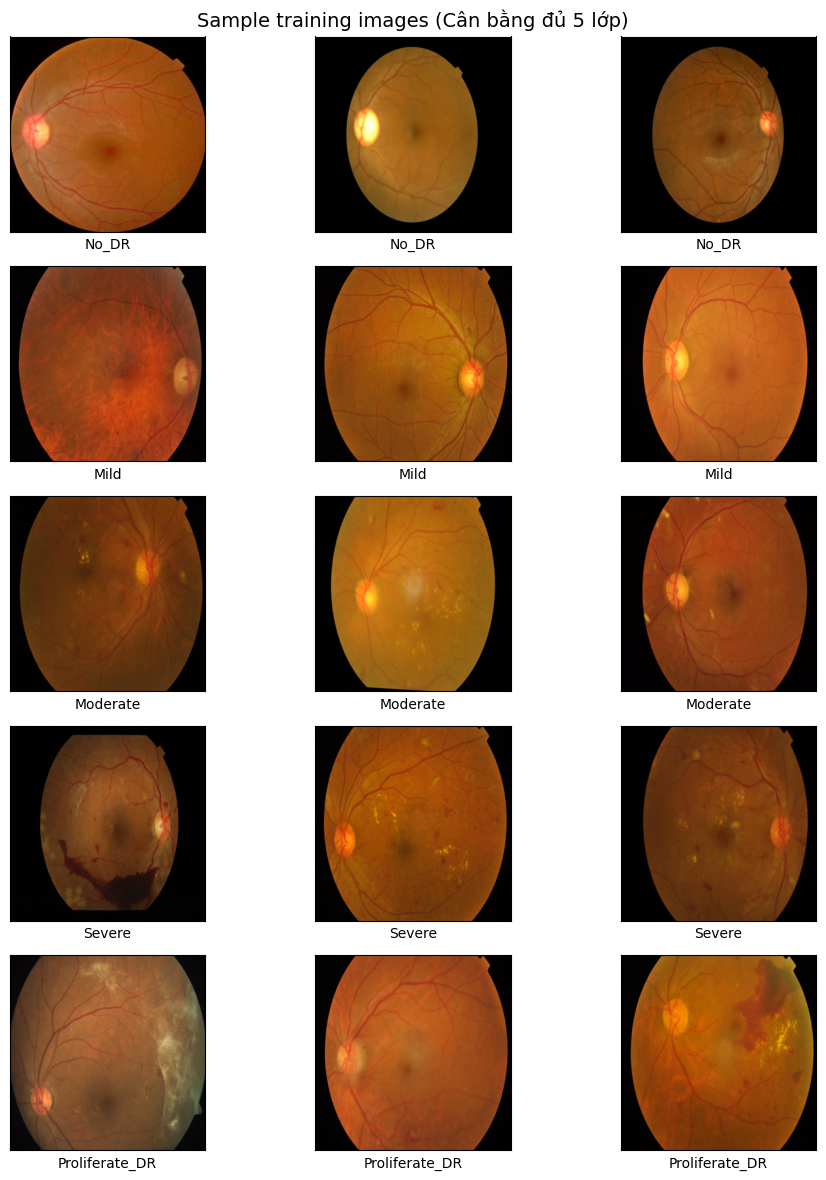

In [11]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

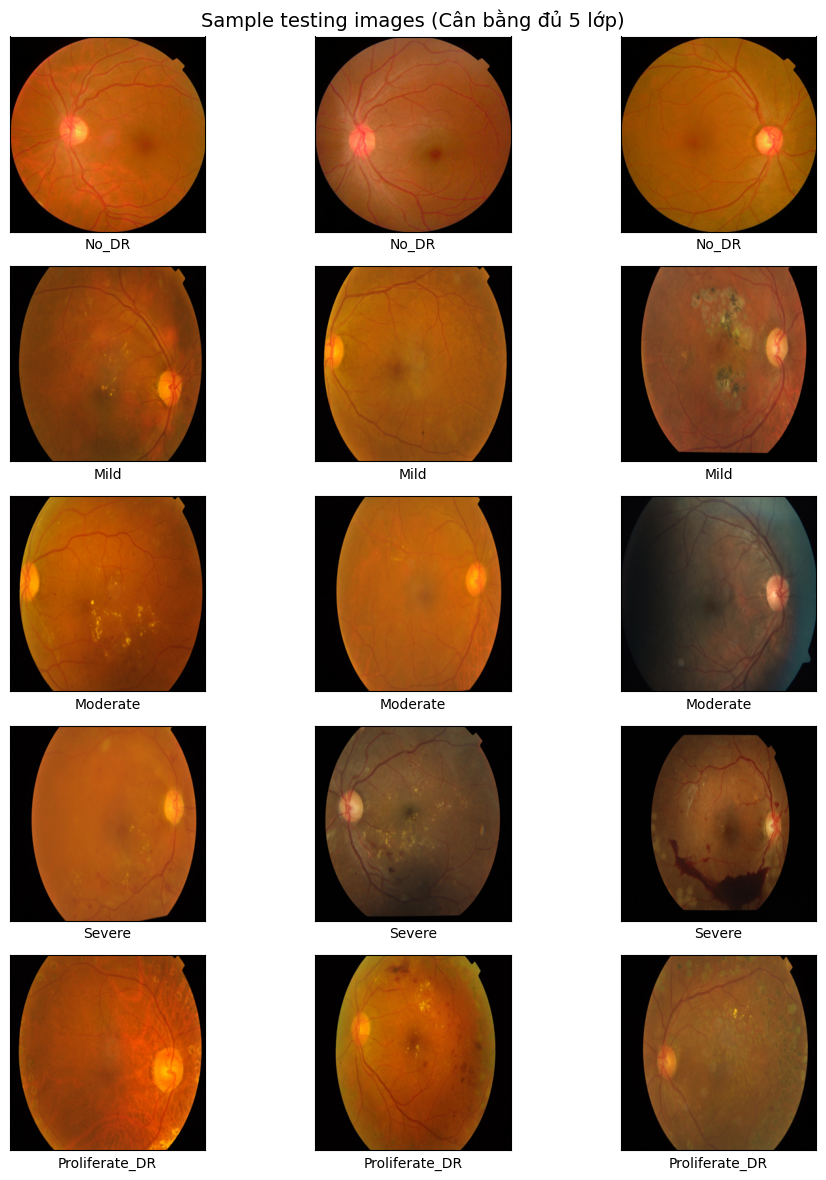

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng ResNet50

In [ ]:
def build_reset50_baseline(input_shape, num_classes):
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base_model.trainable = False
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x) 
    x = BatchNormalization()(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    # Lớp đầu ra 5 classes tương ứng với 5 độ bệnh
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions, name='ResNet50_Aptos')
    
    # Sử dụng Adam với learning rate nhỏ để fine-tune mượt mà hơn
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

In [14]:
model = build_reset50_baseline((IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 306, 306,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 150, 150,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 150, 150,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 152, 152,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 75, 75,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 75, 75,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 75, 75,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 75, 75,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 75, 75,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 75, 75,    │      1,024 │ conv2_block1_3_c

 Total params: 24,779,653 (94.53 MB)

 Trainable params: 1,186,821 (4.53 MB)

 Non-trainable params: 23,592,832 (90.00 MB)

## 5. Compile & Train 

In [15]:
model.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/resnet50_aptos_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=15, 
        restore_best_weights=True, verbose=1
    )
]
history = model.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784814087.268738   24842 service.cc:153] XLA service 0x7e781407d330 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784814087.269210   24842 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784814087.739345   24842 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784814090.428615   24842 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1784814090.910112   24842 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12396__.198
I0000 00:00:1784814102.870491   24842 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



Epoch 1: val_accuracy improved from None to 0.74061, saving model to ../../../data/models/resnet50_aptos_best.keras

Epoch 1: finished saving model to ../../../data/models/resnet50_aptos_best.keras
586/586 - 63s - 107ms/step - accuracy: 0.6126 - loss: 1.1512 - val_accuracy: 0.7406 - val_loss: 0.7565 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.74061 to 0.74403, saving model to ../../../data/models/resnet50_aptos_best.keras

Epoch 2: finished saving model to ../../../data/models/resnet50_aptos_best.keras
586/586 - 29s - 49ms/step - accuracy: 0.6694 - loss: 0.9653 - val_accuracy: 0.7440 - val_loss: 0.7447 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.74403 to 0.75085, saving model to ../../../data/models/resnet50_aptos_best.keras

Epoch 3: finished saving model to ../../../data/models/resnet50_aptos_best.keras
586/586 - 28s - 48ms/step - accuracy: 0.6792 - loss: 0.9079 - val_accuracy: 0.7509 - val_loss: 0.7343 - learning_rate: 0

## 6. Visualize Training

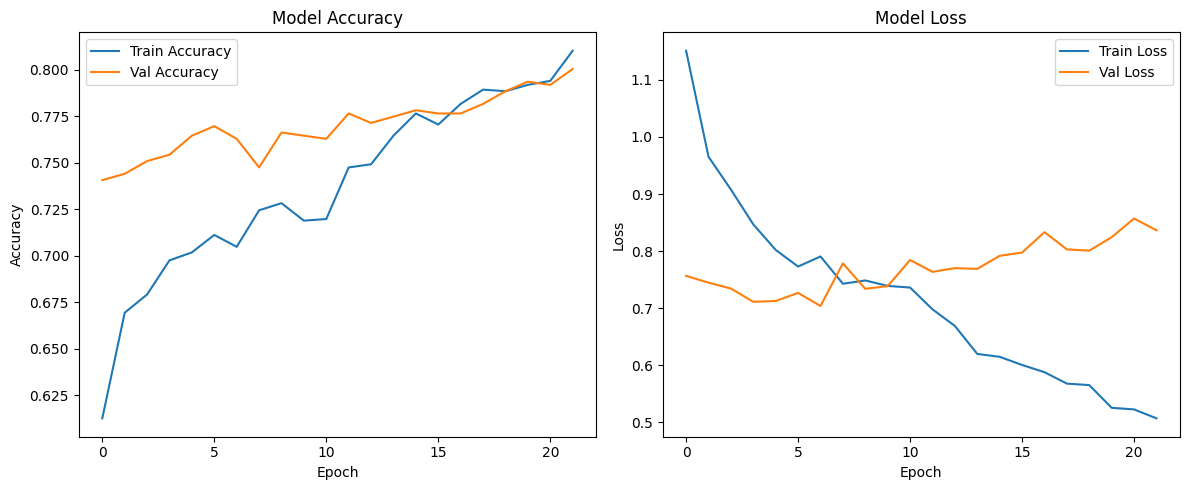

In [16]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7. Evaluate on Test Set

In [17]:
test_loss, test_acc = model.evaluate(test_dataset, verbose=0)
print(f'Test Loss: {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f}') 

Test Loss: 0.6673
Test Accuracy: 0.7896
